In [1]:
pip install tensorflow jupyter ipykernel numpy pandas matplotlib tqdm vector tables scipy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import os
import pickle
from collections import OrderedDict
import sys

n_events = None
target = pd.read_hdf(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\target.h5", stop = n_events) #allows to read data from HDF5 file

# (Pseudo) measurement of the pseudo-data using the nominal MG5 sample
multifold = pd.read_hdf(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold.h5", stop = n_events)
# (Pseudo) measurement of the pseudo-data using the alternative Sherpa sample for unfolding
multifold_sherpa = pd.read_hdf(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold_sherpa.h5", stop = n_events)
multifold_nonDY = pd.read_hdf(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold_nonDY.h5", stop = n_events)
mc_preds = np.load(r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\mc_preds.npy", allow_pickle=True) #allow pickle to load data from a numpy file


In [3]:
### Construct masks for track pT cuts to avoid low momentum events
# note that in the pseudodata they are comparing m5 sim to sherpa sim
mask_trackj1 = np.array(multifold['pT_trackj1'] > 5, dtype='bool')
mask_trackj2 = np.array(multifold['pT_trackj2'] > 5, dtype='bool')

mask_sherpa_trackj1 = np.array(multifold_sherpa['pT_trackj1'] > 5, dtype='bool')
mask_sherpa_trackj2 = np.array(multifold_sherpa['pT_trackj2'] > 5, dtype='bool')

mask_nonDY_trackj1 = np.array(multifold_nonDY['pT_trackj1'] > 5, dtype='bool')
mask_nonDY_trackj2 = np.array(multifold_nonDY['pT_trackj2'] > 5, dtype='bool')

mask_target_trackj1 = np.array(target['pT_trackj1'] > 5, dtype='bool')
mask_target_trackj2 = np.array(target['pT_trackj2'] > 5, dtype='bool')

In [4]:
import numpy as np #array manipulation
import tensorflow as tf #neural network library
from sklearn.model_selection import train_test_split #splits dataset into training set and test set
from sklearn.preprocessing import StandardScaler

from tensorflow import keras
from tensorflow.keras import layers

observables = ['pT_ll', 'pT_l1', 'pT_l2', 'eta_l1', 'eta_l2', 'phi_l1', 'phi_l2', 'y_ll', 'pT_trackj1', 'y_trackj1',
               'phi_trackj1', 'm_trackj1', 'tau1_trackj1', 'tau2_trackj1', 'tau3_trackj1', 'pT_trackj2', 'y_trackj2',
               'phi_trackj2', 'm_trackj2', 'tau1_trackj2', 'tau2_trackj2', 'tau3_trackj2', 'Ntracks_trackj1', 
               'Ntracks_trackj2']

df = multifold
df_sherpa = multifold_sherpa
df_nonDY = multifold_nonDY
target_features = target[observables].values
sherpa_features = multifold_sherpa[observables].values
madgraph_features = multifold[observables].values
nonDY_features = multifold_nonDY[observables].values

scaler = StandardScaler()
X_all = np.concatenate((sherpa_features, madgraph_features))
scaler.fit(X_all)
sherpa_features_scaled = scaler.transform(sherpa_features)
madgraph_features_scaled = scaler.transform(madgraph_features)
target_features_scaled = scaler.transform(target_features)
nonDY_features_scaled = scaler.transform(nonDY_features)

n_features = 24   # number of observables/columns you're using

model = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')   # sigmoid output -> probability between 0 and 1
])


In [7]:
import numpy as np #array manipulation
import tensorflow as tf #neural network library
from sklearn.model_selection import train_test_split #splits dataset into training set and test set
from sklearn.preprocessing import StandardScaler

from tensorflow import keras
from tensorflow.keras import layers

paramX_events = pd.read_hdf(r"C:\Users\HB\Downloads\events_X_1M.h5")
paramY_events = pd.read_hdf(r"C:\Users\HB\Downloads\events_Y_1M.h5")

observables = ['pT_ll', 'pT_l1', 'pT_l2', 'eta_l1', 'eta_l2', 'phi_l1', 'phi_l2', 'y_ll', 'pT_trackj1', 'y_trackj1',
               'phi_trackj1', 'm_trackj1', 'tau1_trackj1', 'tau2_trackj1', 'tau3_trackj1', 'pT_trackj2', 'y_trackj2',
               'phi_trackj2', 'm_trackj2', 'tau1_trackj2', 'tau2_trackj2', 'tau3_trackj2', 'Ntracks_trackj1', 
               'Ntracks_trackj2']


rename_map = {"pt_mumu" : "pT_ll", "pt_mu1" : "pT_l1", "pt_mu2" : "pT_l2", "eta_mu1" : "eta_l1", "eta_mu2" : "eta_l2", "phi_mu1" : "phi_l1", 
"phi_mu2" : "phi_l2", "y_mumu" : "y_ll", "pt_j1" : "pT_trackj1", "y_j1" : "y_trackj1", "phi_j1" : "phi_trackj1", "m_j1" : "m_trackj1", 
"tau1_j1": "tau1_trackj1", "tau2_j1" : "tau2_trackj1", "tau3_j1" : "tau3_trackj1",  "pt_j2" : "pT_trackj2", "y_j2" : "y_trackj2", 
"phi_j2" : "phi_trackj2", "m_j2" : "m_trackj2", "tau1_j2" : "tau1_trackj2", "tau2_j2" : "tau2_trackj2", "tau3_j2": "tau3_trackj2", 
"nch_j1" : "Ntracks_trackj1",  "nch_j2" : "Ntracks_trackj2"
}

paramX_events = paramX_events.rename(columns=rename_map)
paramY_events = paramY_events.rename(columns=rename_map)



paramX_features = paramX_events[observables].values
paramY_features = paramY_events[observables].values
n_features = 24   # number of observables/columns you're using

model = keras.Sequential([
    layers.Input(shape=(n_features,)),
    layers.Dense(64, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')   # sigmoid output -> probability between 0 and 1
])

def train_classifier(paramX_features, paramY_features, model, epochs=20, batch_size=10000): #feature events, 
    #each row is one event, each column is one observable
    # label = 1 for Sherpa, 0 for MadGraph

    scaler = StandardScaler()
    X_all = np.concatenate((paramX_features, paramY_features))
    scaler.fit(X_all)
    paramX_features_scaled = scaler.transform(paramX_features)
    paramY_features_scaled = scaler.transform(paramY_features)

    
    X = np.concatenate((paramX_features_scaled, paramY_features_scaled)) #stacks every Sherpa event on top of every MadGraph event
    #into one big array (full set of inputs network will see)
    y = np.concatenate((np.ones(len(paramX_features)), np.zeros(len(paramY_features)))) #creates corresponding truth
    #labels: 1 for every row coming from Sherpa, 0 for every row coming from MadGraph

    X_train, X_test, y_train, y_test = train_test_split(X, y) #default 75/25 train/test split

    model.compile(loss='binary_crossentropy',   # plain BCE -- no per-event weights needed 
                  #standard loss for 2-class problem (with sigmoid output)
                  #penalizes model based on how far its predicted probability was from the true label
                  #minimizing this loss is what makes model's output converge toward true probability that given event
                  #is sherpa vs Madgraph
                  optimizer='Adam', #algorithm that updates network's weights eaching training steo
                  metrics=['accuracy']) #if accuracy stays near 50%, both sims look statistically indistinguishable
    # if accuracy is well above 50%, there's real learnable structure differentiating them


    history = model.fit(X_train, y_train,
                         epochs=epochs,
                         batch_size=batch_size,
                         validation_data=(X_test, y_test))
    return model, history, X_test, y_test

trained_model, history, X_test, y_test = train_classifier(paramX_features, paramY_features, model = model)

Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5070 - loss: 0.6990 - val_accuracy: 0.5139 - val_loss: 0.6934
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5155 - loss: 0.6931 - val_accuracy: 0.5162 - val_loss: 0.6926
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5177 - loss: 0.6925 - val_accuracy: 0.5172 - val_loss: 0.6923
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5195 - loss: 0.6921 - val_accuracy: 0.5199 - val_loss: 0.6922
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5215 - loss: 0.6918 - val_accuracy: 0.5204 - val_loss: 0.6921
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5231 - loss: 0.6916 - val_accuracy: 0.5197 - val_loss: 0.6922
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5239 - loss: 0.6914 - val_accuracy: 0.5206 - val_loss: 0.6919
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5243 - loss: 0.6912 - val_accuracy: 0.5215 - val_loss:

In [8]:
sherpa_pred = model.predict(sherpa_features_scaled).flatten()
madgraph_pred = model.predict(madgraph_features_scaled).flatten()
nonDY_pred = model.predict(nonDY_features_scaled).flatten()

10201/10201 ━━━━━━━━━━━━━━━━━━━━ 5s 494us/step
13063/13063 ━━━━━━━━━━━━━━━━━━━━ 7s 502us/step
13544/13544 ━━━━━━━━━━━━━━━━━━━━ 7s 508us/step


In [66]:
print(model.predict(sherpa_features_scaled).shape)
print(model.predict(sherpa_features_scaled).flatten())

10201/10201 ━━━━━━━━━━━━━━━━━━━━ 30s 3ms/step
(326430, 1)
10201/10201 ━━━━━━━━━━━━━━━━━━━━ 29s 3ms/step
[0.57954204 0.41536164 0.40776289 ... 0.5015665  0.45802072 0.19650008]


In [67]:
sherpa_pred.shape

(326430,)

In [9]:
target_pred = model.predict(target_features_scaled).flatten()

747437/747437 ━━━━━━━━━━━━━━━━━━━━ 468s 626us/step


DIAGNOSTICS

9939/9939 ━━━━━━━━━━━━━━━━━━━━ 42s 4ms/step
10102/10102 ━━━━━━━━━━━━━━━━━━━━ 43s 4ms/step


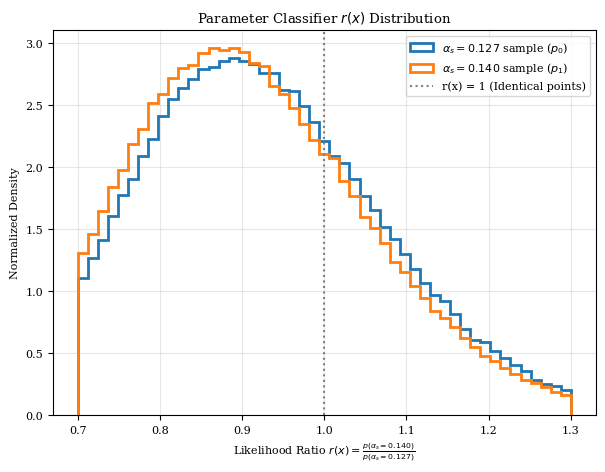

In [19]:
import matplotlib.pyplot as plt
import numpy as np

paramX_features_scaled = scaler.transform(paramX_features)
paramY_features_scaled = scaler.transform(paramY_features)

# 1. Get predictions d(x) from your alpha_s classifier model
# (Class 1 = 0.140, Class 0 = 0.127)
d_0127 = model.predict(paramX_features_scaled).flatten()
d_0140 = model.predict(paramY_features_scaled).flatten()

# 2. Clip slightly to avoid division by zero
eps = 1e-7
d_0127 = np.clip(d_0127, eps, 1 - eps)
d_0140 = np.clip(d_0140, eps, 1 - eps)

# 3. Calculate likelihood ratio r(x) = p(0.140) / p(0.127)
r_0127 = d_0127 / (1 - d_0127)
r_0140 = d_0140 / (1 - d_0140)

# 4. Plot both r(x) distributions
bins = np.linspace(0.7, 1.3, 50)  # Focused bin range around 1

plt.figure(figsize=(7, 5))
plt.hist(
    r_0127,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label=r"$\alpha_s = 0.127$ sample ($p_0$)",
)
plt.hist(
    r_0140,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label=r"$\alpha_s = 0.140$ sample ($p_1$)",
)

plt.axvline(
    1.0, color="gray", linestyle=":", label="r(x) = 1 (Identical points)"
)
plt.xlabel(
    r"Likelihood Ratio $r(x) = \frac{p(\alpha_s=0.140)}{p(\alpha_s=0.127)}$"
)
plt.ylabel("Normalized Density")
plt.title(r"Parameter Classifier $r(x)$ Distribution")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [10]:
df["classifier_score"] = madgraph_pred
df_sherpa["classifier_score"] = sherpa_pred
df_nonDY["classifier_score"] = nonDY_pred
target["classifier_score"] = target_pred

everything from pseudodata_flexible_rebinning

In [11]:

# Update the file path to your local file
local_file_path = r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold.h5"

multifold_util = r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold_util.py"

if os.path.isfile(local_file_path):
    print("Skipping download -- data already exists locally.")
else:
    print("File not found at the specified path.")

try:
    sys.path.append(os.path.dirname(multifold_util)) #adds multifold_util to list of directories that python searches for modules
    from multifold_util import *
    import numpy as np
    import pandas as pd
    pd.options.mode.chained_assignment = None
    import matplotlib.pyplot as plt
    from tqdm import tqdm
    import os
    import pickle

    if os.path.isfile(multifold_util):
        print("Done!")
    else:
        raise Exception("File does not exist.")

except Exception as e:
    print(f"There was an error: {e}")

Skipping download -- data already exists locally.
Done!


In [12]:
bins_dict = ibu_bins # defined in demo_functions.py
#bins_dict['Ntracks_trackj1'] = [0.5, 2.0, 5.0] # example of how to modify binning for a given variable

print(f"Loaded bins for {len(bins_dict)} observables:")
for obs, bins in bins_dict.items():
    print("{:>15} with {:2} bins [{:.1f} ... {:.1f}]".format(obs,len(bins),bins[0],bins[-1]))
    # print("  {}, {} bins: {}".format(obs,len(bins),bins))

#only set this to truw when you change binning definitions and change back to false after running the uncertainty cell
Force_recalculate = True

Loaded bins for 24 observables:
          pT_l1 with  7 bins [25.0 ... 800.0]
          pT_l2 with  7 bins [25.0 ... 400.0]
         eta_l1 with 15 bins [-2.5 ... 2.5]
         eta_l2 with 15 bins [-2.5 ... 2.5]
         phi_l1 with 17 bins [-3.1 ... 3.1]
         phi_l2 with 17 bins [-3.1 ... 3.1]
     pT_trackj1 with  7 bins [5.0 ... 1000.0]
     pT_trackj2 with  5 bins [5.0 ... 500.0]
      y_trackj1 with 19 bins [-2.5 ... 2.5]
      y_trackj2 with 11 bins [-2.5 ... 2.5]
    phi_trackj1 with 17 bins [-3.1 ... 3.1]
    phi_trackj2 with 17 bins [-3.1 ... 3.1]
          pT_ll with  6 bins [200.0 ... 1000.0]
           y_ll with 15 bins [-2.5 ... 2.5]
Ntracks_trackj1 with  7 bins [0.5 ... 39.5]
Ntracks_trackj2 with  6 bins [0.5 ... 34.5]
      m_trackj1 with  7 bins [0.0 ... 70.0]
      m_trackj2 with  5 bins [0.0 ... 40.0]
   tau1_trackj1 with  8 bins [0.0 ... 0.9]
   tau1_trackj2 with  6 bins [0.0 ... 0.9]
   tau2_trackj1 with  8 bins [0.0 ... 0.5]
   tau2_trackj2 with  6 bins [0.0 ..

In [13]:
# List of systematic uncertainties, stored as weights in the dataset
#ssystematic uncertainties are systematic biases or gaps in modelling of the detector and theory
event_systs     = [col for col in multifold.keys() if col.startswith("weights_muEff")] + ['weights_pileup']
theory_systs    = [col for col in multifold.keys() if col.startswith("weights_theory")]
track_systs     = [col for col in multifold.keys() if col.startswith("weights_track")]
muon_systs      = [col for col in multifold.keys() if col.startswith("weights_muCal")]

# List of stochastic uncertainty names
#stochastic uncertainties are statistical, random fluctuations
mc_stat_systs   = [col for col in multifold.keys() if col.startswith("weights_bootstrap_mc")]
data_stat_systs = [col for col in multifold.keys() if col.startswith("weights_bootstrap_data")]
ensemble_systs  = [col for col in multifold.keys() if col.startswith("weights_ensemble")]

In [14]:
uncertainties_filepath = r"C:\Users\HB\OneDrive\Desktop\OmniFold\pseudodata_uncertainties.p"

if os.path.exists(uncertainties_filepath) and not Force_recalculate:
    print("Using pre-calculated uncertainties.") 
    uncertainties = np.load(uncertainties_filepath, allow_pickle=True)
else:
    print("Recalculating uncertainties from scratch.")
    uncertainties = {}

    for i in tqdm(range(24), desc="Unfolded vars"): # number of unfolded observables
        var = list(bins_dict.items())[i][0] #need list to create something indexable
        bins = np.array(list(bins_dict.items())[i][1])
        bin_centers = 0.5 * (bins[1:] + bins[:-1])

        if "trackj1" in var: 
            df = multifold[mask_trackj1]
            df_sherpa = multifold_sherpa[mask_sherpa_trackj1]
            df_nonDY = multifold_nonDY[mask_nonDY_trackj1]
        elif "trackj2" in var:
            df = multifold[mask_trackj2]
            df_sherpa = multifold_sherpa[mask_sherpa_trackj2]
            df_nonDY = multifold_nonDY[mask_nonDY_trackj2]
        else:
            df = multifold
            df_sherpa = multifold_sherpa
            df_nonDY = multifold_nonDY
            
        nom, _ = np.histogram(df[var], bins=bins, weights=df.weights_nominal)    

        final_event          = calculate_uncertainty(df, var, bins, event_systs)
        final_theory         = calculate_uncertainty(df, var, bins, theory_systs)
        final_track          = calculate_uncertainty(df, var, bins, track_systs)
        final_muon           = calculate_uncertainty(df, var, bins, muon_systs)
        final_mc_stat        = calculate_stat_uncertainty(df, var, bins, mc_stat_systs)
        final_data_stat      = calculate_stat_uncertainty(df, var, bins, data_stat_systs)
        final_nn_init        = calculate_stat_uncertainty(df, var, bins, ensemble_systs)/np.sqrt(len(ensemble_systs))
        
        ### Unfolding (DD)
        syst, _ = np.histogram(df[var], bins=bins, weights=df.weights_dd)
        target_dd, _ = np.histogram(df[var], bins=bins, weights=df.target_dd)
        final_unfolding_dd = 100*np.sqrt((syst-target_dd)**2)/target_dd

        ### Unfolding (HV)
        syst, _ = np.histogram(df_sherpa[var], bins=bins, weights=df_sherpa.weights_nominal)
        smoothed_hv_syst_signed = smooth_uncertainty(syst-nom, bin_centers)
        final_unfolding_hv = 100*np.sqrt((smoothed_hv_syst_signed)**2)/nom

        ### Sum these together in quadrature
        final_unfolding = np.sqrt(final_unfolding_hv**2 + final_unfolding_dd**2)

        ### Luminosity 
        syst, _ = np.histogram(df[var], bins=bins, weights=df.weights_lumi)
        final_lumi = 100*np.sqrt((syst-nom)**2)/nom

        ### Top Background 
        syst, _ = np.histogram(df[var], bins=bins, weights=df.weights_topBackground)
        final_top = 100*np.sqrt((syst-nom)**2)/nom

        ### Non-Strong Background
        syst, _ = np.histogram(df_nonDY[var], bins=bins, weights=df_nonDY.weights_nominal)
        final_nonDY = 100*np.sqrt((syst-nom)**2)/nom

        final_exp = np.sqrt(final_lumi**2 + final_muon**2 + final_track**2 + final_event**2)
        uncertainties[var+"_exp"] = final_exp
        uncertainties[var+"_theory"] = final_theory
        uncertainties[var+"_mc_stat"] = np.sqrt(final_mc_stat**2 + final_nn_init**2)
        uncertainties[var+"_data_stat"] = final_data_stat
        uncertainties[var+"_unfolding"] = final_unfolding
        uncertainties[var+"_top"] = final_top
        uncertainties[var+"_nonDY"] = final_nonDY

        total = np.sqrt(
            + final_theory**2 
            + final_exp**2
            + final_mc_stat**2
            + final_data_stat**2
            + final_unfolding**2
            + final_top**2
            + final_nonDY**2
        )
        uncertainties[var+"_total"] = total

        print(f"Saving calculated uncertainties to folder: {uncertainties_filepath}")
        with open(uncertainties_filepath, "wb") as f:
            pickle.dump(uncertainties, f)
        print("Done")


Recalculating uncertainties from scratch.


Unfolded vars:   4%|▍         | 1/24 [00:03<01:23,  3.61s/it]

Saving calculated uncertainties to folder: C:\Users\HB\OneDrive\Desktop\OmniFold\pseudodata_uncertainties.p
Done


Unfolded vars:   8%|▊         | 2/24 [00:06<01:14,  3.38s/it]

Saving calculated uncertainties to folder: C:\Users\HB\OneDrive\Desktop\OmniFold\pseudodata_uncertainties.p
Done


...

Saving calculated uncertainties to folder: C:\Users\HB\OneDrive\Desktop\OmniFold\pseudodata_uncertainties.p
Done


Unfolded vars:  96%|█████████▌| 23/24 [01:16<00:03,  3.37s/it]

Saving calculated uncertainties to folder: C:\Users\HB\OneDrive\Desktop\OmniFold\pseudodata_uncertainties.p
Done


Unfolded vars: 100%|██████████| 24/24 [01:19<00:00,  3.31s/it]

Saving calculated uncertainties to folder: C:\Users\HB\OneDrive\Desktop\OmniFold\pseudodata_uncertainties.p
Done


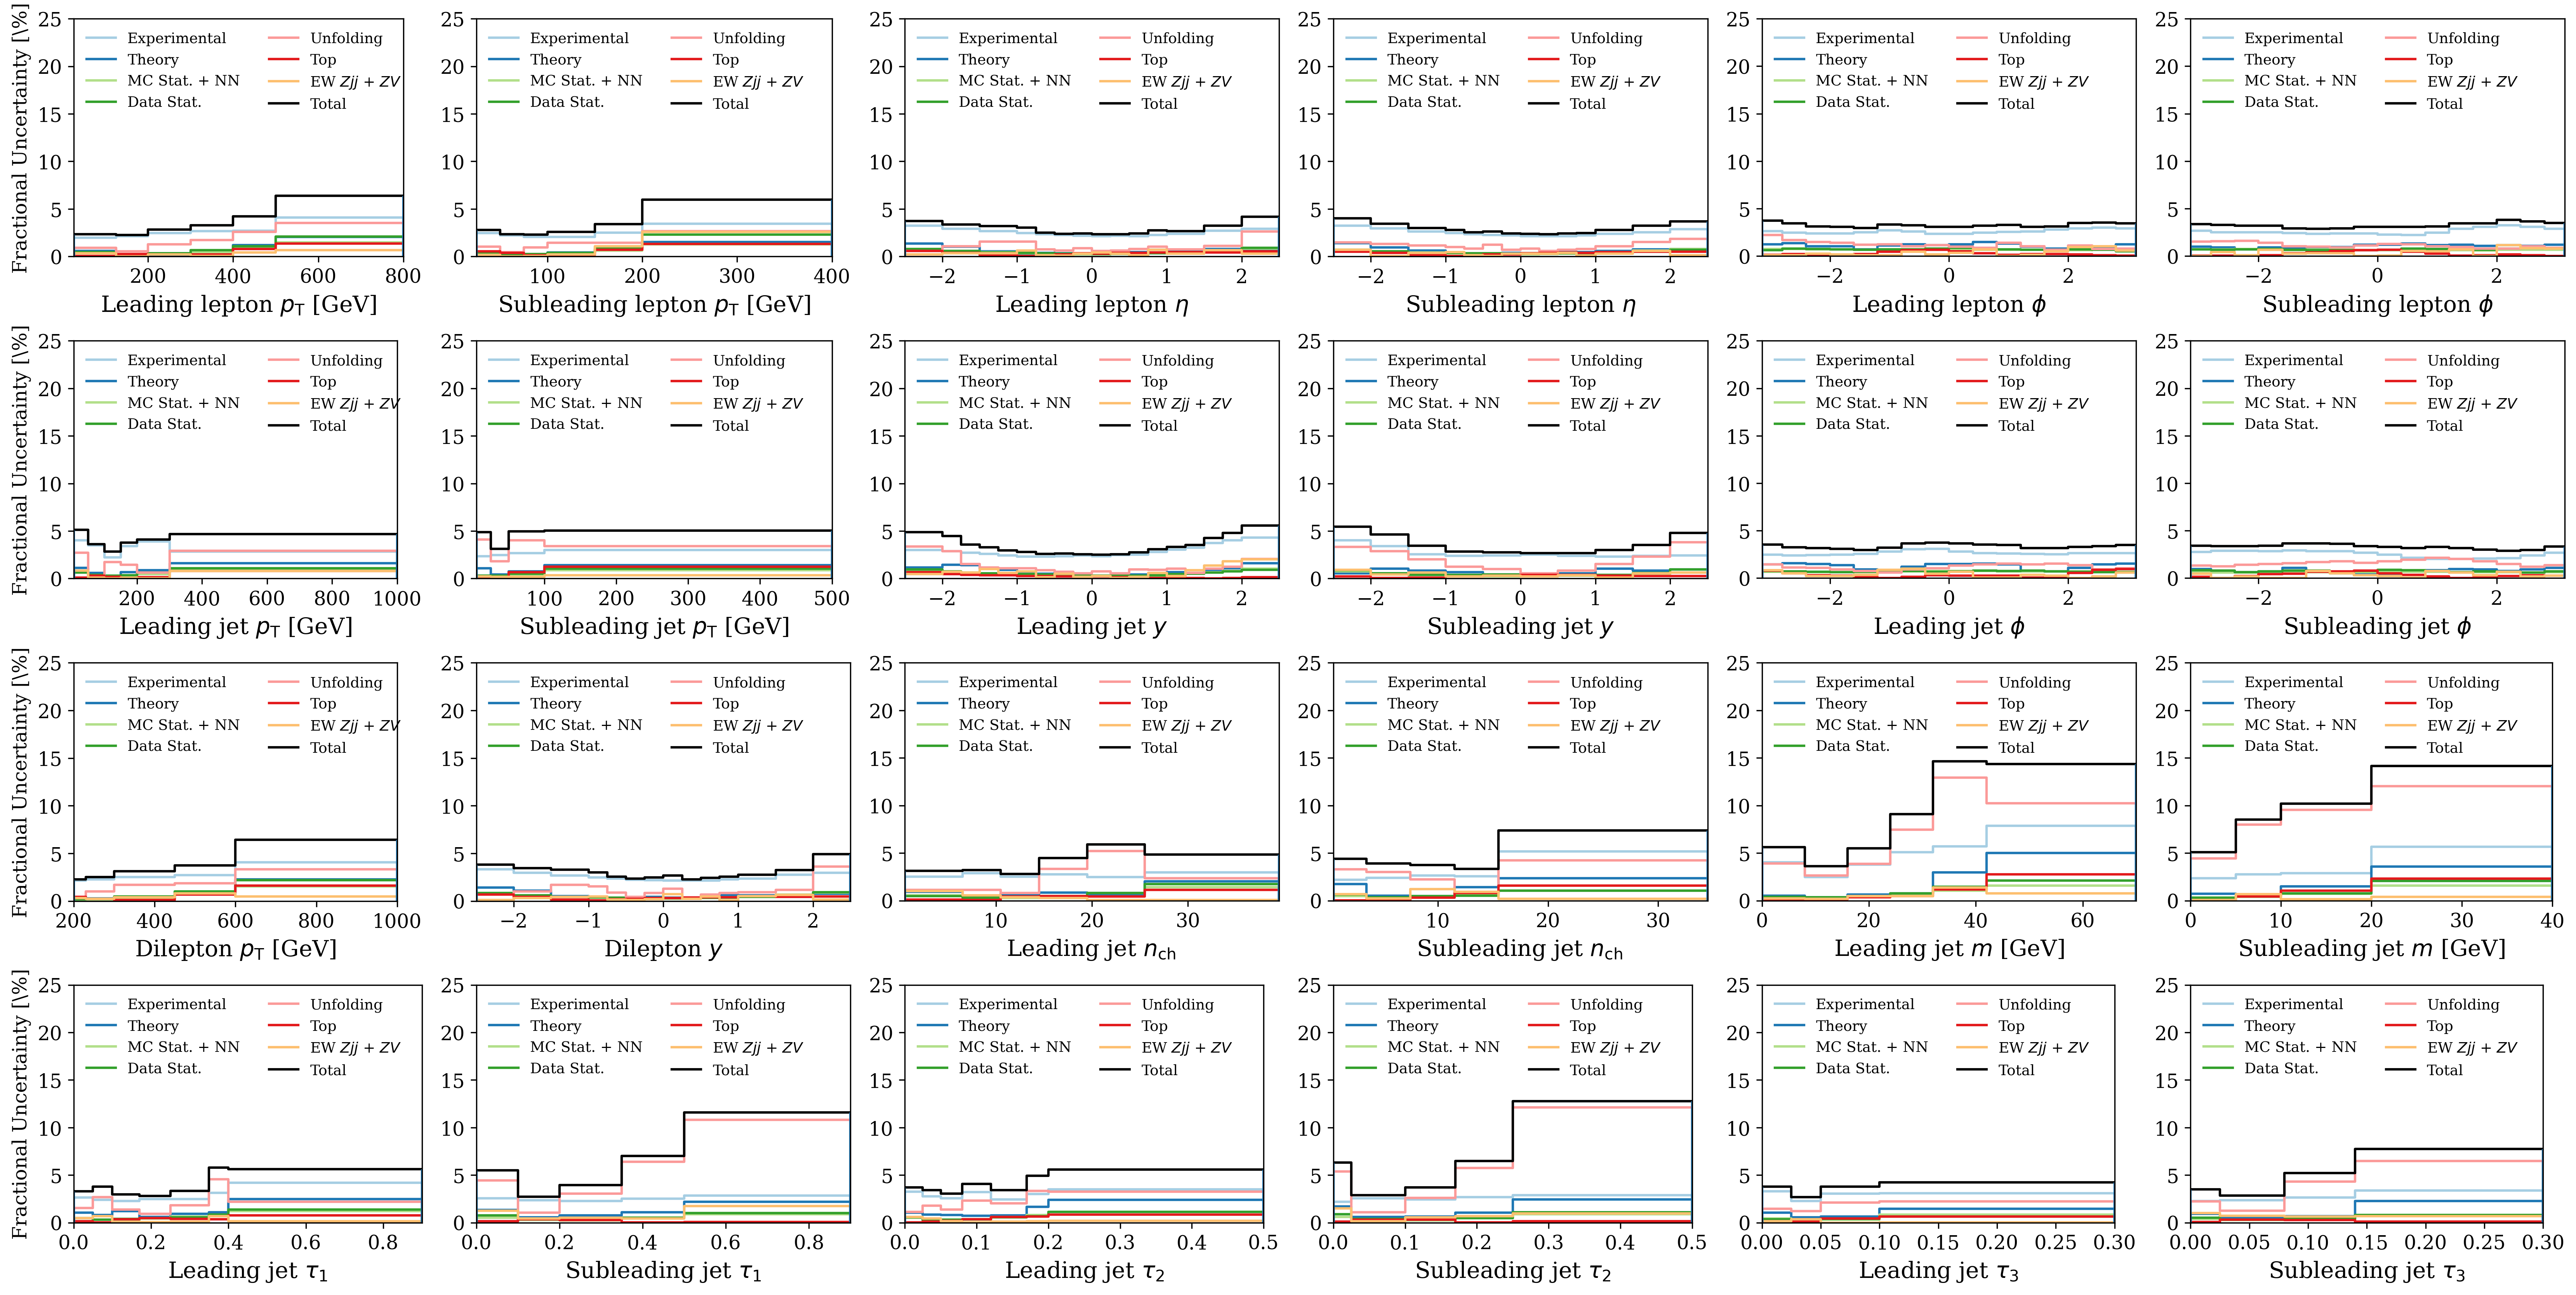

In [15]:
import matplotlib
matplotlib.rcParams['text.usetex'] = False
fig = plt.figure(figsize=(22,11), dpi=300, constrained_layout=True)
subfigs = fig.subfigures(4, 6)

for i, subfig in enumerate(subfigs.flat):
    ax = subfig.subplots(1, 1)
    colors = [plt.cm.Paired(i) for i in range(20)]
    var = list(bins_dict.items())[i][0]
    bins = np.array(list(bins_dict.items())[i][1])

    ax.step(bins, np.concatenate([[uncertainties[var+'_exp'][0]],uncertainties[var+'_exp']]),              label = "Experimental",       color=colors[0],    )
    ax.step(bins, np.concatenate([[uncertainties[var+'_theory'][0]],uncertainties[var+'_theory']]),        label = "Theory",             color=colors[1],    )
    ax.step(bins, np.concatenate([[uncertainties[var+'_mc_stat'][0]],uncertainties[var+'_mc_stat']]),      label = "MC Stat. + NN",      color=colors[2],    )
    ax.step(bins, np.concatenate([[uncertainties[var+'_data_stat'][0]],uncertainties[var+'_data_stat']]),  label = "Data Stat.",         color=colors[3],    )
    ax.step(bins, np.concatenate([[uncertainties[var+'_unfolding'][0]],uncertainties[var+'_unfolding']]),  label = "Unfolding",          color=colors[4]     )
    ax.step(bins, np.concatenate([[uncertainties[var+'_top'][0]],uncertainties[var+'_top']]),              label = "Top",                color=colors[5],    )
    ax.step(bins, np.concatenate([[uncertainties[var+'_nonDY'][0]],uncertainties[var+'_nonDY']]),          label = r"EW $Zjj$ + $ZV$",   color=colors[6],    )
    ax.step(bins, np.concatenate([[uncertainties[var+'_total'][0]],uncertainties[var+'_total']]),          label = "Total",              color='black',      )

    ### draw lines at the beginning and end of the first and last bins, for plotting purposes
    label_list = ['exp', 'theory', 'mc_stat', 'data_stat', 'unfolding', 'top', 'nonDY', 'total']
    for label in label_list:
        plt.vlines(x=bins[0], ymin=0, ymax=uncertainties[var+'_'+label][0])
        plt.vlines(x=bins[-1], ymin=0, ymax=uncertainties[var+'_'+label][-1])

    ax.xaxis.set_tick_params(labelsize=12)
    ax.yaxis.set_tick_params(labelsize=12)
    if i % 6 == 0: ax.set_ylabel(r"Fractional Uncertainty [\%]", fontsize=12)
    ax.legend(fontsize=9, loc='upper left', ncol=2, frameon=False)
    ax.set_xlim([bins[0], bins[-1]])
    ax.set_ylim([0, 25])
    ax.set_xlabel(plot_labels[var], fontsize=14);

plt.savefig(r"C:\Users\HB\OneDrive\Desktop\OmniFold\total_systs")

Plots: 100%|██████████| 24/24 [00:28<00:00,  1.18s/it]


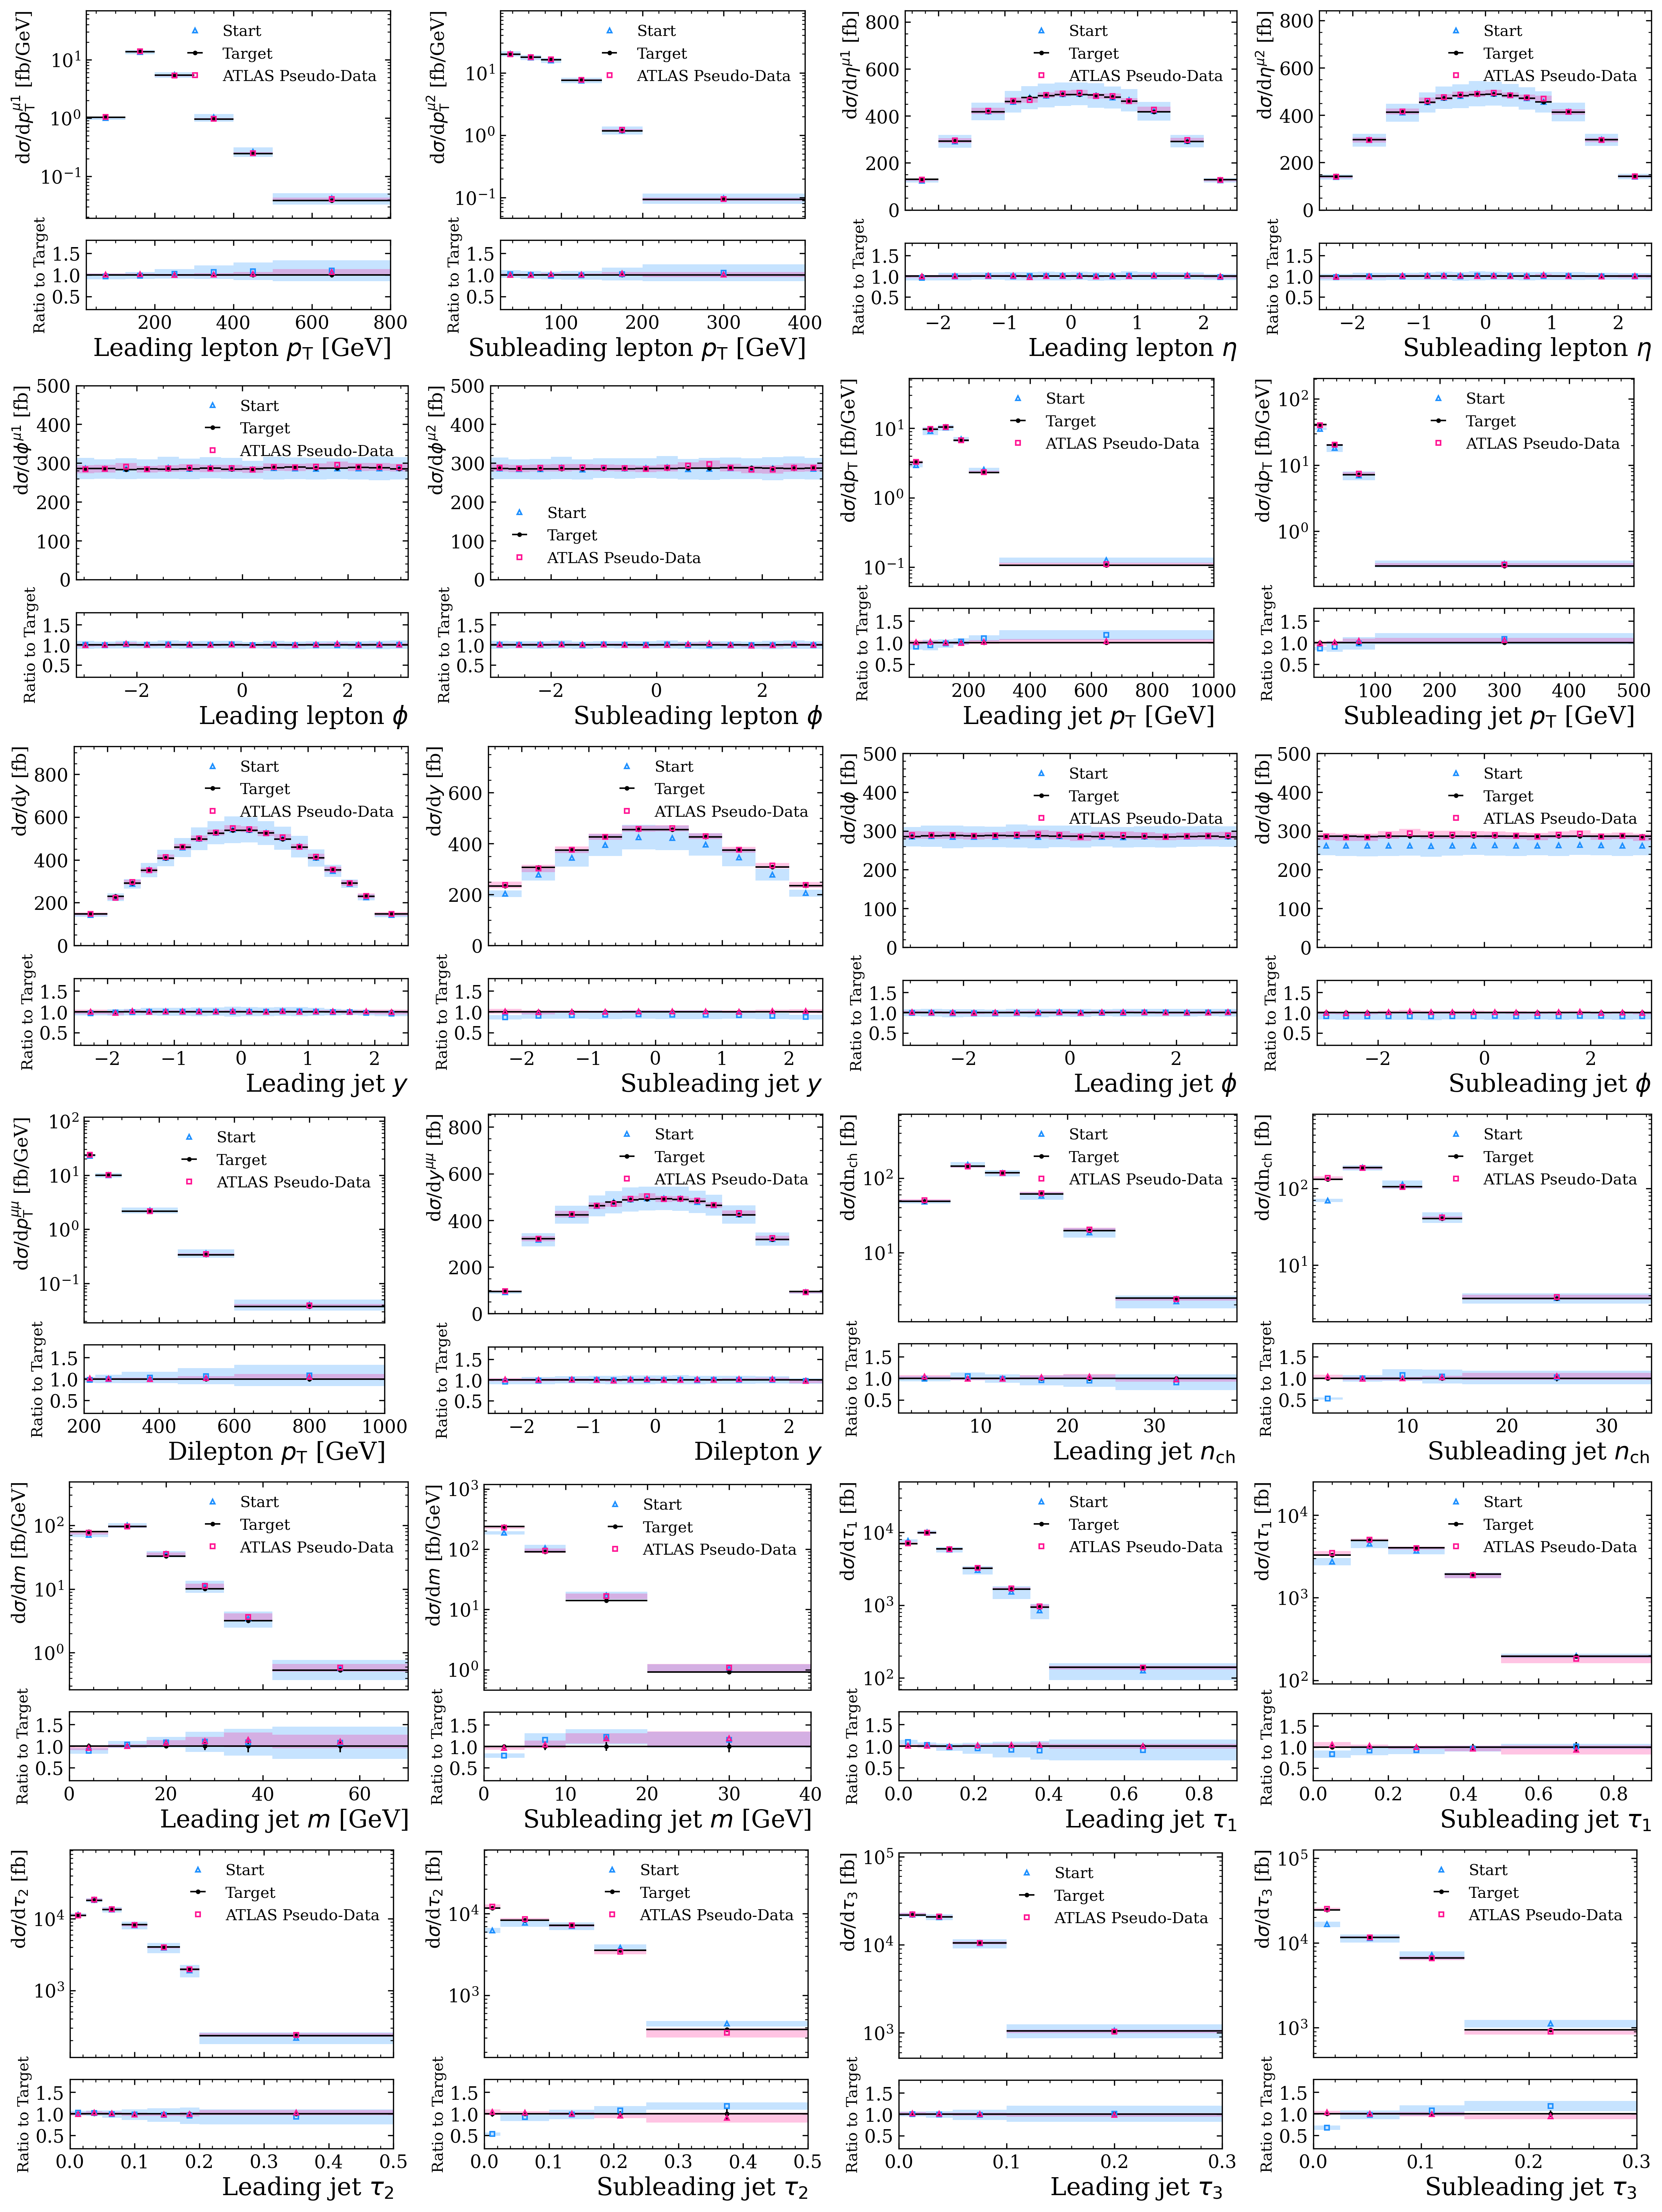

In [16]:
fig = plt.figure(figsize=(15, 20), dpi=300, constrained_layout=True)
subfigs = fig.subfigures(6, 4)

for i, subfig in enumerate(tqdm(subfigs.flat, desc="Plots")):  
    axs = subfig.subplots(2, 1, sharex=True, sharey=False, gridspec_kw={'height_ratios': [3, 1]})
    
    var = list(bins_dict.items())[i][0]
    bins = np.array(list(bins_dict.items())[i][1])
    
    # Calculate bin centers and widths properly inside the loop
    bin_centers = 0.5 * (bins[1:] + bins[:-1])
    bin_widths = bins[1:] - bins[:-1]
    
    if "trackj1" in var: 
        df = multifold[mask_trackj1]
    elif "trackj2" in var:
        df = multifold[mask_trackj2]
    else:
        df = multifold    
    
    ### 1. Starting distribution
    counts = mc_preds[i]['mgfxfx_counts']
    start_density = counts / lumi / bin_widths
    start_error = mc_preds[i]['mgfxfx_err'] / mc_preds[i]['mgfxfx_counts']
    _ = make_error_boxes(axs[0], bin_centers, start_density, np.vstack([bin_widths/2, bin_widths/2]), np.vstack([start_density*start_error, start_density*start_error]), facecolor='dodgerblue', alpha=0.25, marker="^", label='Start')
    
    ### 2. Target distribution
    target_density, _, _ = axs[0].hist(target[var], bins=bins, density=True, weights=target.weight_mc, color='k', alpha=0)
    target_density *= np.sum(target.weight_mc)
    axs[0].errorbar(bin_centers, target_density, xerr=bin_widths/2, yerr=None, marker=".", linestyle="None", color="k", alpha=1, ecolor='k', label="Target", markersize=4, linewidth=1)

    ### 3. MultiFold distribution
    multifold_density, _, _ = axs[0].hist(multifold[var], weights=multifold.weights_nominal, bins=bins, histtype='step', color='black', linewidth=2, density=True, alpha=0)
    multifold_density *= np.sum(multifold.weights_nominal)
    _ = make_error_boxes(axs[0], bin_centers, multifold_density, np.vstack([bin_widths/2, bin_widths/2]), np.vstack([multifold_density*uncertainties[var+"_total"]/100, multifold_density*uncertainties[var+"_total"]/100]), facecolor='deeppink', alpha=0.25, marker="s", label='ATLAS Pseudo-Data')

    ### Main Plot (axs[0]) Styling
    axs[0].minorticks_on()
    axs[0].xaxis.set_tick_params(labelsize=12, which='both', direction='in', top=True)
    axs[0].yaxis.set_tick_params(labelsize=12, which='both', direction='in', right=True)
    axs[0].set_ylabel(labels[var], fontsize=12, labelpad=2, loc='top')
    axs[0].set_ylim([0, 1.7 * max(max(target_density), max(multifold_density))])
    
    ### Log vs Linear Scale constraints
    if 'phi' not in var and 'eta' not in var and 'y' not in var:
        axs[0].set_yscale('log')
        axs[0].set_ylim([0.5 * min(min(target_density), min(multifold_density)), 5 * max(max(target_density), max(multifold_density))])
    elif 'phi' in var:
        axs[0].set_ylim(0, 500)
    
    axs[0].legend(fontsize=10, frameon=False, loc='best')

    axs[1].errorbar(bin_centers, np.ones(len(bin_centers)), xerr=bin_widths/2, yerr=uncertainties[var+"_total"]/100, marker=".", linestyle="None", color="k", alpha=1,  ecolor='k', label="ATLAS Pseudo-Data", markersize=4, linewidth=1)
    _ = make_error_boxes(axs[1], bin_centers, start_density/target_density, np.vstack([bin_widths/2,bin_widths/2]), np.vstack([(start_density/target_density)*start_error, (start_density/target_density)*start_error]), facecolor='dodgerblue', alpha=0.25, marker="s", label=r'Start')
    _ = make_error_boxes(axs[1], bin_centers, multifold_density/target_density, np.vstack([bin_widths/2,bin_widths/2]), np.vstack([(multifold_density/target_density)*uncertainties[var+"_total"]/100, (multifold_density/target_density)*uncertainties[var+"_total"]/100]), facecolor='deeppink', alpha=0.25, marker="^", label=r'MG5+Py8 + $\mathbf{X}$')
    axs[1].set_xlim(bins[0], bins[-1])
    axs[1].set_ylim([0.2,1.8])
    axs[1].xaxis.set_tick_params(labelsize=12, which='both', direction='in', top=True)
    axs[1].yaxis.set_tick_params(labelsize=12, which='both', direction='in', right=True)
    axs[1].set_ylabel('Ratio to Target', fontsize=10, labelpad=2, loc='center')
    axs[1].set_xlabel(plot_labels[var], fontsize=16, labelpad=2, loc='right');
    
# Save the final consolidated multi-panel figure
plt.savefig(r"C:\Users\HB\OneDrive\Desktop\OmniFold\nominal_diff_xsec.pdf")

In [17]:
#SAVING THIS CODE HERE IN CASE

main_path = r"C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata"


#Add statement that notifies when a bin has less than 5000 events, statistical uncertainty should be under 15%
#change from matplotlib code to np code
### Plot Ntracks_trackj1 with custom bins using weight_mc (no mc_preds needed)
"""uncertainties = {
    "exp": final_exp,
    "theory": final_theory,
    "mc_stat": np.sqrt(final_mc_stat**2 + final_nn_init**2),
    "data_stat": final_data_stat,
    "unfolding": final_unfolding,
    "top": final_top,
    "nonDY": final_nonDY_unc,
}

uncertainties["total"] = np.sqrt(
    uncertainties["exp"]**2
    + uncertainties["theory"]**2
    + uncertainties["mc_stat"]**2
    + uncertainties["data_stat"]**2
    + uncertainties["unfolding"]**2
    + uncertainties["top"]**2
    + uncertainties["nonDY"]**2
)"""

#adding in quadrature accounts for the fact that each source of uncertainy is an independent random error, that don't all propagate in the same direction

def custom_binning(var, binslist):
    lumi = 138.96
    bins = np.array(binslist)
    bin_centers = 0.5 * (bins[1:] + bins[:-1])
    bin_widths  = np.diff(bins)

    fig, axs = plt.subplots(2, 1, sharex=True, figsize=(5, 5), dpi=150,
                            gridspec_kw={'height_ratios': [3, 1]}, constrained_layout=True)
    
    if "trackj1" in var:
        df       = multifold[mask_trackj1]
        df_sherpa = multifold_sherpa[mask_sherpa_trackj1]
        df_nonDY  = multifold_nonDY[mask_nonDY_trackj1]
    elif "trackj2" in var:
        df        = multifold[mask_trackj2]
        df_sherpa = multifold_sherpa[mask_sherpa_trackj2]
        df_nonDY  = multifold_nonDY[mask_nonDY_trackj2]
    else:
        df        = multifold
        df_sherpa = multifold_sherpa
        df_nonDY  = multifold_nonDY

    nom, _ = np.histogram(df[var], bins=bins, weights=df.weights_nominal) #np.histogram returns counts and bin edges, so use _ because we defined bin_edges already
    final_event     = calculate_uncertainty(df, var, bins, event_systs)
    final_theory    = calculate_uncertainty(df, var, bins, theory_systs)
    final_track     = calculate_uncertainty(df, var, bins, track_systs)
    final_muon      = calculate_uncertainty(df, var, bins, muon_systs)
    final_mc_stat   = calculate_stat_uncertainty(df, var, bins, mc_stat_systs)
    final_data_stat = calculate_stat_uncertainty(df, var, bins, data_stat_systs)
    final_nn_init   = calculate_stat_uncertainty(df, var, bins, ensemble_systs) / np.sqrt(len(ensemble_systs))


    #weights_nominal are final omnifold weights after unfolding procedure --> estimate of particle-level distribution
    #weights_dd are variations of those weights  to estimate unfolding uncertainty
    #final_nn_init is uncertainty coming from nn initialization (differing results due to differing random seeds)
    #nom, syst, and target are all histograms using different weights


    
    syst, _      = np.histogram(df[var], bins=bins, weights=df.weights_dd)
    target_dd, _ = np.histogram(df[var], bins=bins, weights=df.target_dd)
    final_unfolding_dd = 100 * np.sqrt((syst - target_dd)**2) / target_dd
    
    syst, _  = np.histogram(df_sherpa[var], bins=bins, weights=df_sherpa.weights_nominal)
    smoothed = smooth_uncertainty(syst - nom, bin_centers)
    final_unfolding_hv = 100 * np.sqrt(smoothed**2) / nom
    final_unfolding    = np.sqrt(final_unfolding_hv**2 + final_unfolding_dd**2)
    
    syst, _ = np.histogram(df[var], bins=bins, weights=df.weights_lumi)
    final_lumi = 100 * np.sqrt((syst - nom)**2) / nom
    syst, _ = np.histogram(df[var], bins=bins, weights=df.weights_topBackground)
    final_top = 100 * np.sqrt((syst - nom)**2) / nom
    syst, _ = np.histogram(df_nonDY[var], bins=bins, weights=df_nonDY.weights_nominal)
    final_nonDY_unc = 100 * np.sqrt((syst - nom)**2) / nom
    
    final_exp = np.sqrt(final_lumi**2 + final_muon**2 + final_track**2 + final_event**2)
    total_unc = np.sqrt(final_theory**2 + final_exp**2 + final_mc_stat**2 +
                        final_data_stat**2 + final_unfolding**2 + final_top**2 + final_nonDY_unc**2)
        
    
        
    # --- Starting distribution: DY + non-DY, exact equivalent of mc_preds at any binning ---
    dy_counts,       _ = np.histogram(df[var],       bins=bins, weights=df.weight_mc)
    nonDY_counts,    _ = np.histogram(df_nonDY[var], bins=bins, weights=df_nonDY.weight_mc)
    dy_counts_sq,    _ = np.histogram(df[var],       bins=bins, weights=df.weight_mc**2)
    nonDY_counts_sq, _ = np.histogram(df_nonDY[var], bins=bins, weights=df_nonDY.weight_mc**2)
    total_counts    = dy_counts #+ nonDY_counts
    total_counts_sq = dy_counts_sq #+ nonDY_counts_sq
    start_density = total_counts / bin_widths
    start_error   = np.sqrt(total_counts_sq) / total_counts  # relative Poisson error

    _ = make_error_boxes(axs[0], bin_centers, start_density,
                         np.vstack([bin_widths/2, bin_widths/2]),
                         np.vstack([start_density*start_error, start_density*start_error]),
                         facecolor='dodgerblue', alpha=0.25, marker="^", label='Start')
    
    
    ###Target density
    
    target_counts, _ = np.histogram(target[var], bins = bins, weights = target.weight_mc)
    target_density = target_counts / bin_widths
    axs[0].errorbar(bin_centers, target_density, xerr=bin_widths/2, yerr=None, marker=".",
                   linestyle="None", color="k", alpha = 1, ecolor= "k", label="Target", markersize=4, linewidth=1)

   

    multifold_counts, _ = np.histogram(multifold[var], bins=bins, weights=multifold.weights_nominal)
    multifold_density = multifold_counts / bin_widths

    
    _ = make_error_boxes(axs[0], bin_centers, multifold_density,
                         np.vstack([bin_widths/2, bin_widths/2]),
                         np.vstack([multifold_density*total_unc/100, multifold_density*total_unc/100]),
                         facecolor='deeppink', alpha=0.25, marker="s", label='ATLAS Pseudo-Data')
    
    if 'phi' not in var and 'eta' not in var and 'y' not in var:
        axs[0].set_yscale('log')
        axs[0].set_ylim([0.5*min(min(target_density), min(multifold_density)), 5 * max(max(target_density), max(multifold_density))])
    axs[0].set_ylabel(labels[var], fontsize=11, loc='top')
    axs[0].legend(fontsize=9, frameon=False)
    
    axs[1].errorbar(bin_centers, np.ones(len(bin_centers)), xerr=bin_widths/2,
                    yerr=total_unc/100, marker=".", linestyle="None", color="k", markersize=4)
    _ = make_error_boxes(axs[1], bin_centers, start_density/target_density,
                         np.vstack([bin_widths/2, bin_widths/2]),
                         np.vstack([start_density/target_density*start_error]*2),
                         facecolor='dodgerblue', alpha=0.25, marker="^", label='Start')
    _ = make_error_boxes(axs[1], bin_centers, multifold_density/target_density,
                         np.vstack([bin_widths/2, bin_widths/2]),
                         np.vstack([multifold_density/target_density*total_unc/100]*2),
                         facecolor='deeppink', alpha=0.25, marker="s", label='ATLAS Pseudo-Data')
    axs[1].set_xlim(bins[0], bins[-1])
    axs[1].set_ylim([0.2, 1.8])
    axs[1].set_ylabel('Ratio to Target', fontsize=9)
    axs[1].set_xlabel(plot_labels[var], fontsize=12)

    plt.savefig(os.path.join(main_path, f"custom_binning_{var}"))
    plt.show()

    uncertainties = {
    "exp": final_exp,
    "theory": final_theory,
    "mc_stat": np.sqrt(final_mc_stat**2 + final_nn_init**2),
    "data_stat": final_data_stat,
    "unfolding": final_unfolding,
    "top": final_top,
        "nonDY": final_nonDY_unc,
    }
    
    uncertainties["total"] = np.sqrt(
        uncertainties["exp"]**2
        + uncertainties["theory"]**2
        + uncertainties["mc_stat"]**2
        + uncertainties["data_stat"]**2
        + uncertainties["unfolding"]**2
        + uncertainties["top"]**2
        + uncertainties["nonDY"]**2
    )

    fig_unc, ax_unc = plt.subplots(figsize=(5,4), dpi=150)

    colors = plt.cm.Paired(range(8))
    
    for color, label in zip(colors,
                            ["exp","theory","mc_stat","data_stat",
                             "unfolding","top","nonDY","total"]):

        ax_unc.step(
            bins,
            np.r_[uncertainties[label][0], uncertainties[label]],
            where="pre",
            label=label,
            color="black" if label=="total" else color
        )
    
        ax_unc.vlines(bins[0], 0, uncertainties[label][0],
                      color="black" if label=="total" else color)
        ax_unc.vlines(bins[-1], 0, uncertainties[label][-1],
                      color="black" if label=="total" else color)
    
        ax_unc.set_xlim(bins[0], bins[-1])
        ax_unc.set_ylim(0, 25)
        ax_unc.set_ylabel("Fractional uncertainty [%]")
        ax_unc.set_xlabel(plot_labels[var])
        ax_unc.legend(frameon=False, fontsize=8, ncol=2)

    
    plt.savefig(os.path.join(main_path, f"uncertainties_{var}"))
    plt.show() #need to save fig before plotting so it doesn't save blank image


labels['classifier_score'] = 'Classifier Score'
plot_labels['classifier_score'] = 'Classifier Score'  # used for the x-axis label too



C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold_util.py:67: RuntimeWarning: divide by zero encountered in divide
  final_uncert = 100*np.sqrt(total_uncert)/nom
C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold_util.py:67: RuntimeWarning: invalid value encountered in divide
  final_uncert = 100*np.sqrt(total_uncert)/nom
C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold_util.py:77: RuntimeWarning: divide by zero encountered in divide
  final_stat = 100*np.std(stat, axis=0)/nom
C:\Users\HB\OneDrive\Desktop\OmniFold\files\pseudodata\multifold_util.py:77: RuntimeWarning: invalid value encountered in divide
  final_stat = 100*np.std(stat, axis=0)/nom
C:\Users\HB\AppData\Local\Temp\ipykernel_30916\3794940565.py:72: RuntimeWarning: invalid value encountered in divide
  final_unfolding_dd = 100 * np.sqrt((syst - target_dd)**2) / target_dd
C:\Users\HB\AppData\Local\Temp\ipykernel_30916\3794940565.py:76: RuntimeWarning: divide by zero encountered in 

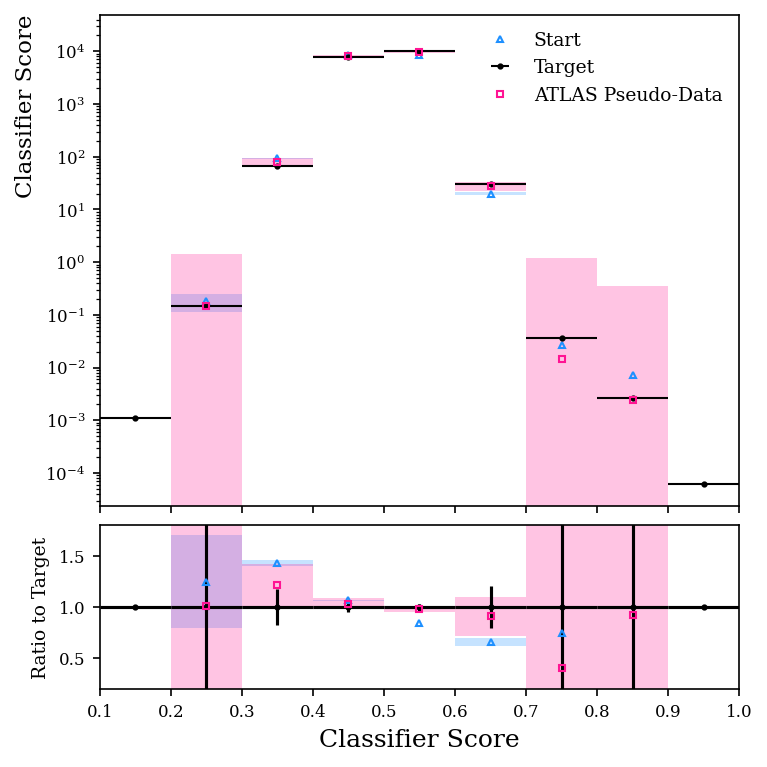

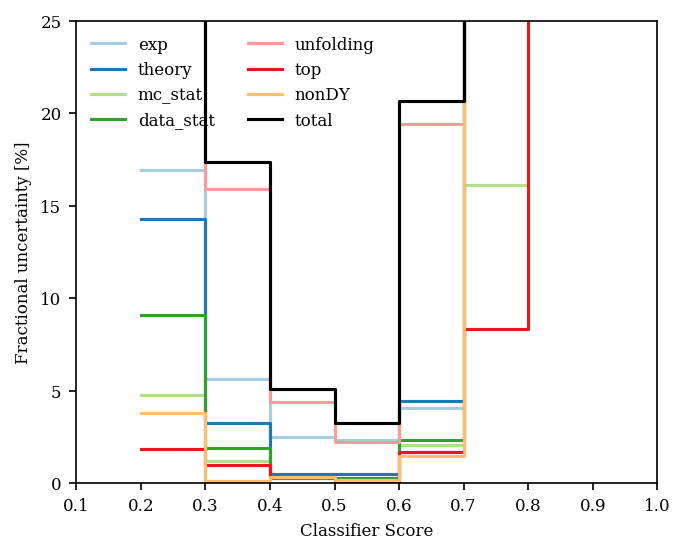

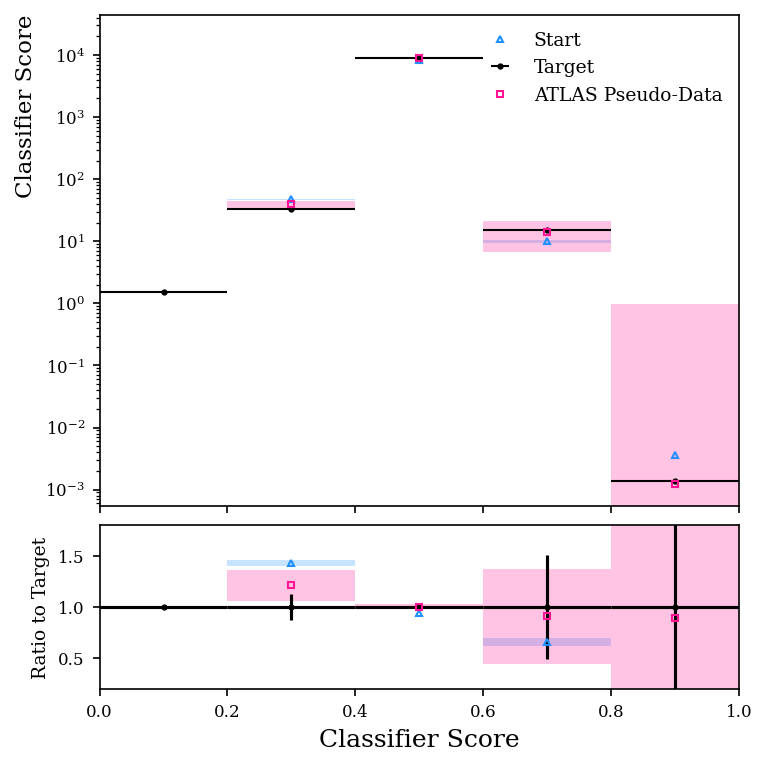

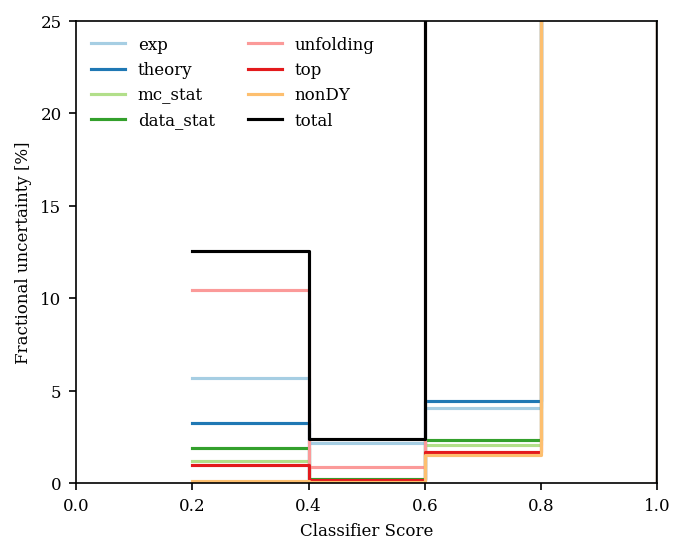

In [18]:
labels['classifier_score'] = 'Classifier Score'
plot_labels['classifier_score'] = 'Classifier Score'

custom_binning("classifier_score", [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
custom_binning("classifier_score", [0, 0.2, 0.4, 0.6, 0.8, 1.0])